# 03 — LSTM Multi-horizonte

Treino e avaliação do modelo preditivo (`src/models/dataset.py` e `src/models/lstm.py`).

**Decisões de modelagem:**
- **Alvo = log-retornos futuros**, não níveis de preço: `y_h(t) = ln P(t+h) − ln P(t)` para horizontes de **21, 63 e 126 dias úteis** (~1, 3 e 6 meses). Prever retornos evita que a rede aprenda a não-estacionariedade; o motor prescritivo reconstrói a trajetória via `P(t+h) = P(t)·exp(y_h)`.
- **Entrada**: janela de 63 dias (~3 meses) com 16 features estacionárias (retornos, posição vs. médias móveis, volatilidade, spread robusta, base físico×futuro, sazonalidade, bienalidade, Selic).
- **Normalização**: `StandardScaler` ajustado **apenas no treino**.
- **Sequências construídas dentro de cada split** — janelas e alvos nunca cruzam a fronteira treino/validação/teste.
- **Arquitetura**: LSTM(64) → LSTM(32) → Dense(32) → Dense(3), dropout 0.2, early stopping pela validação (o teste permanece cego até o backtest do notebook 04).
- **Baselines**: (i) passeio aleatório (retorno previsto = 0); (ii) **curva de futuros** — retorno implícito no futuro ICE em R$ + base sazonal (`rmse_curva`), que é o que um produtor com acesso à B3 já tem de graça e, portanto, o baseline que a LSTM precisa vencer.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
plt.rcParams['figure.figsize'] = (12, 4)

from src.models.dataset import HORIZONS, TARGET, prepare_splits
from src.models.lstm import evaluate

data = prepare_splits()
for name in ['train', 'val', 'test']:
    print(f"{name:6s}: X{data[name]['X'].shape} y{data[name]['y'].shape}")

train : X(3940, 63, 26) y(3940, 3)
val   : X(372, 63, 26) y(372, 3)
test  : X(417, 63, 26) y(417, 3)


## 1. Treino

Carrega o modelo salvo se existir; para re-treinar do zero, apague `models/lstm_multihorizonte.keras` ou rode `python -m src.models.lstm`.

In [2]:
import keras
from src.models.lstm import train

RETREINAR = True   # C1: treina do zero (seed 42, reprodutível em CPU) e regrava models/
model_path = ROOT / 'models' / 'lstm_multihorizonte.keras'
if model_path.exists() and not RETREINAR:
    model = keras.saving.load_model(model_path)
    history = None
    print('Modelo carregado de', model_path.name)
else:
    model, data, history = train(data, verbose=0)
    from src.models.predict import compute_residual_sigma
    print('σ residual regravado:', compute_residual_sigma(model, data))
model.summary()

σ residual regravado: {21: 0.08875790983438492, 63: 0.15313374996185303, 126: 0.1177782416343689}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 63, 32)         │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,995 (132.80 KB)

 Trainable params: 11,331 (44.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,664 (88.54 KB)

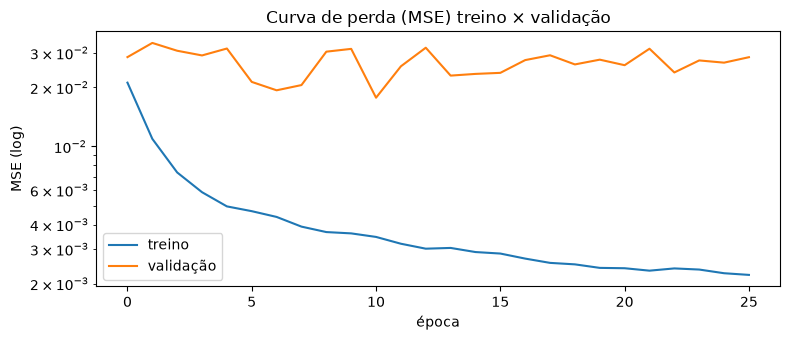

In [3]:
FIG = ROOT / 'reports' / 'figures'
if history is not None:
    h = pd.DataFrame(history.history)[['loss', 'val_loss']]
    ax = h.plot(title='Curva de perda (MSE) treino × validação', logy=True, figsize=(8, 3.5))
    ax.set_xlabel('época'); ax.set_ylabel('MSE (log)'); ax.legend(['treino', 'validação'])
    plt.tight_layout(); plt.savefig(FIG / '02_curva_perda.png', dpi=300, facecolor='white')

## 2. Métricas na validação (o teste segue cego)

`rmse_ret` deve ficar abaixo de `rmse_naive` (passeio aleatório) para o modelo agregar valor; `acerto_direcao` acima de 50% indica sinal direcional útil para o motor prescritivo.

In [4]:
met_train = evaluate(model, data['train'], data['df'])
met_val = evaluate(model, data['val'], data['df'])
print('Treino:'); display(met_train.round(4))
print('Validação:'); display(met_val.round(4))

Treino:


,rmse_ret,mae_ret,rmse_naive,mape_preco_%,acerto_direcao_%,rmse_curva,acerto_direcao_curva_%
horizonte,,,,,,,
21d,0.0495,0.0377,0.0717,3.7861,74.9239,0.0928,54.2893
63d,0.0450,0.0353,0.1285,3.5461,87.8426,0.1340,54.2386
126d,0.0487,0.0365,0.1904,3.5910,90.7614,0.1831,59.1371


Validação:


,rmse_ret,mae_ret,rmse_naive,mape_preco_%,acerto_direcao_%,rmse_curva,acerto_direcao_curva_%
horizonte,,,,,,,
21d,0.0960,0.0670,0.0907,7.0457,56.7204,0.1071,61.2903
63d,0.1661,0.1449,0.1767,15.2892,74.4624,0.1560,68.5484
126d,0.1278,0.1042,0.2356,10.7816,91.6667,0.1927,75.2688


## 3. Previsto × real na validação

Preço reconstruído a cada dia da validação: `P(t+h) = P(t)·exp(ŷ_h)`, comparado ao preço real em `t+h`.

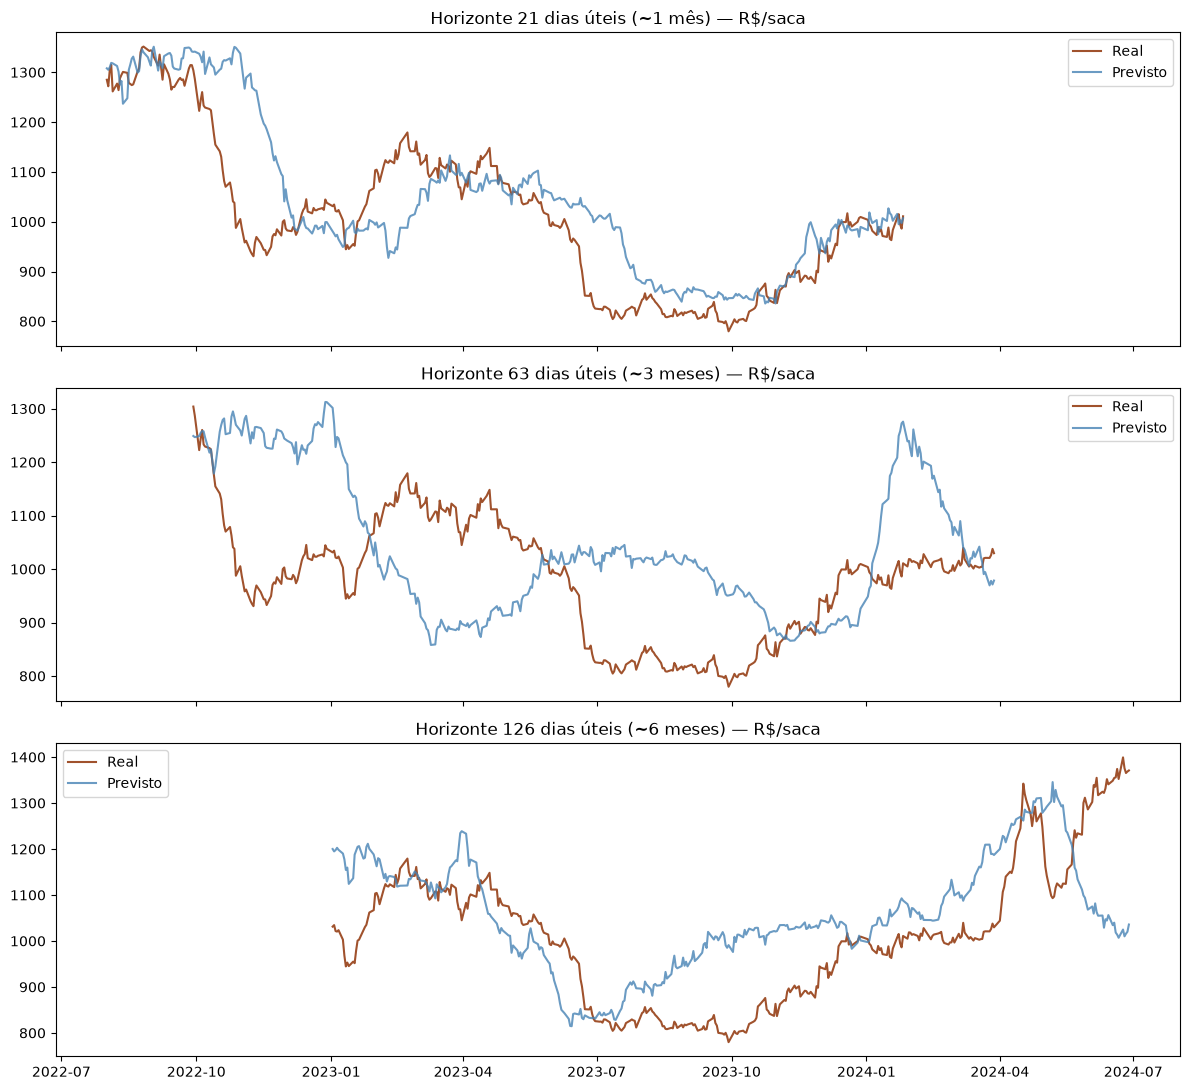

In [5]:
df = data['df']
val = data['val']
pred = model.predict(val['X'], verbose=0)
price = df[TARGET]

fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(12, 11), sharex=True)
for i, (h, ax) in enumerate(zip(HORIZONS, axes)):
    p_now = price.loc[val['dates']].to_numpy()
    idx_future = df.index.get_indexer(val['dates']) + h
    p_real = price.iloc[idx_future].to_numpy()
    p_pred = p_now * np.exp(pred[:, i])
    dates_future = df.index[idx_future]
    ax.plot(dates_future, p_real, color='sienna', label='Real')
    ax.plot(dates_future, p_pred, color='steelblue', alpha=0.8, label='Previsto')
    ax.set_title(f'Horizonte {h} dias úteis (~{h//21} {"mês" if h==21 else "meses"}) — R$/saca')
    ax.legend()
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'figures' / '03_previsto_realizado_validacao.png', dpi=300, facecolor='white')


## 4. Dispersão previsto × real (retornos)

Pontos no 1º e 3º quadrantes = direção acertada.

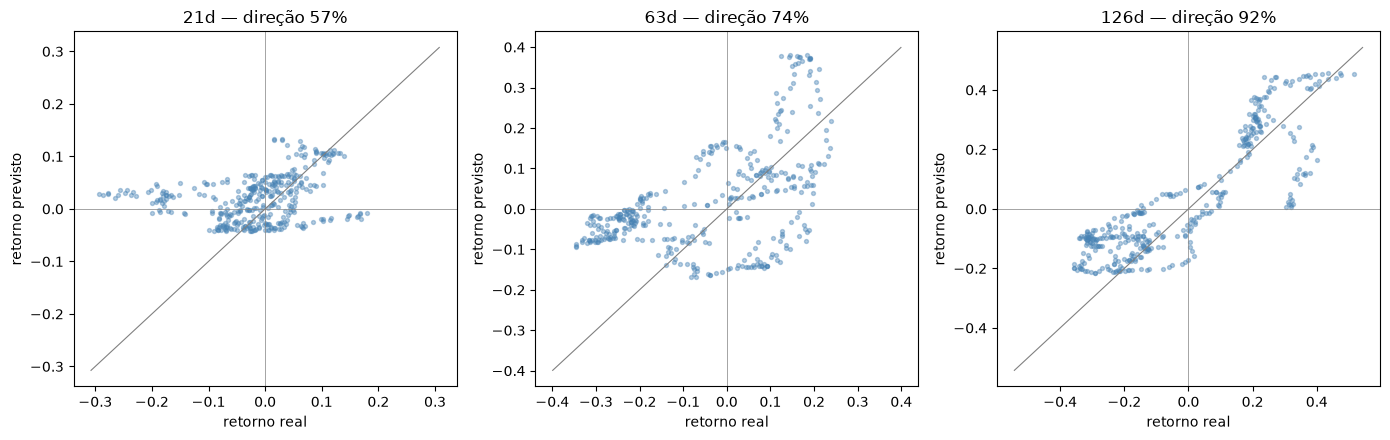

In [6]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(14, 4.5))
for i, (h, ax) in enumerate(zip(HORIZONS, axes)):
    ax.scatter(val['y'][:, i], pred[:, i], s=8, alpha=0.4, color='steelblue')
    lim = max(abs(val['y'][:, i]).max(), abs(pred[:, i]).max()) * 1.05
    ax.plot([-lim, lim], [-lim, lim], color='gray', lw=0.8)
    ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
    ax.set_xlabel('retorno real'); ax.set_ylabel('retorno previsto')
    acerto = (np.sign(pred[:, i]) == np.sign(val['y'][:, i])).mean() * 100
    ax.set_title(f'{h}d — direção {acerto:.0f}%')
plt.tight_layout()

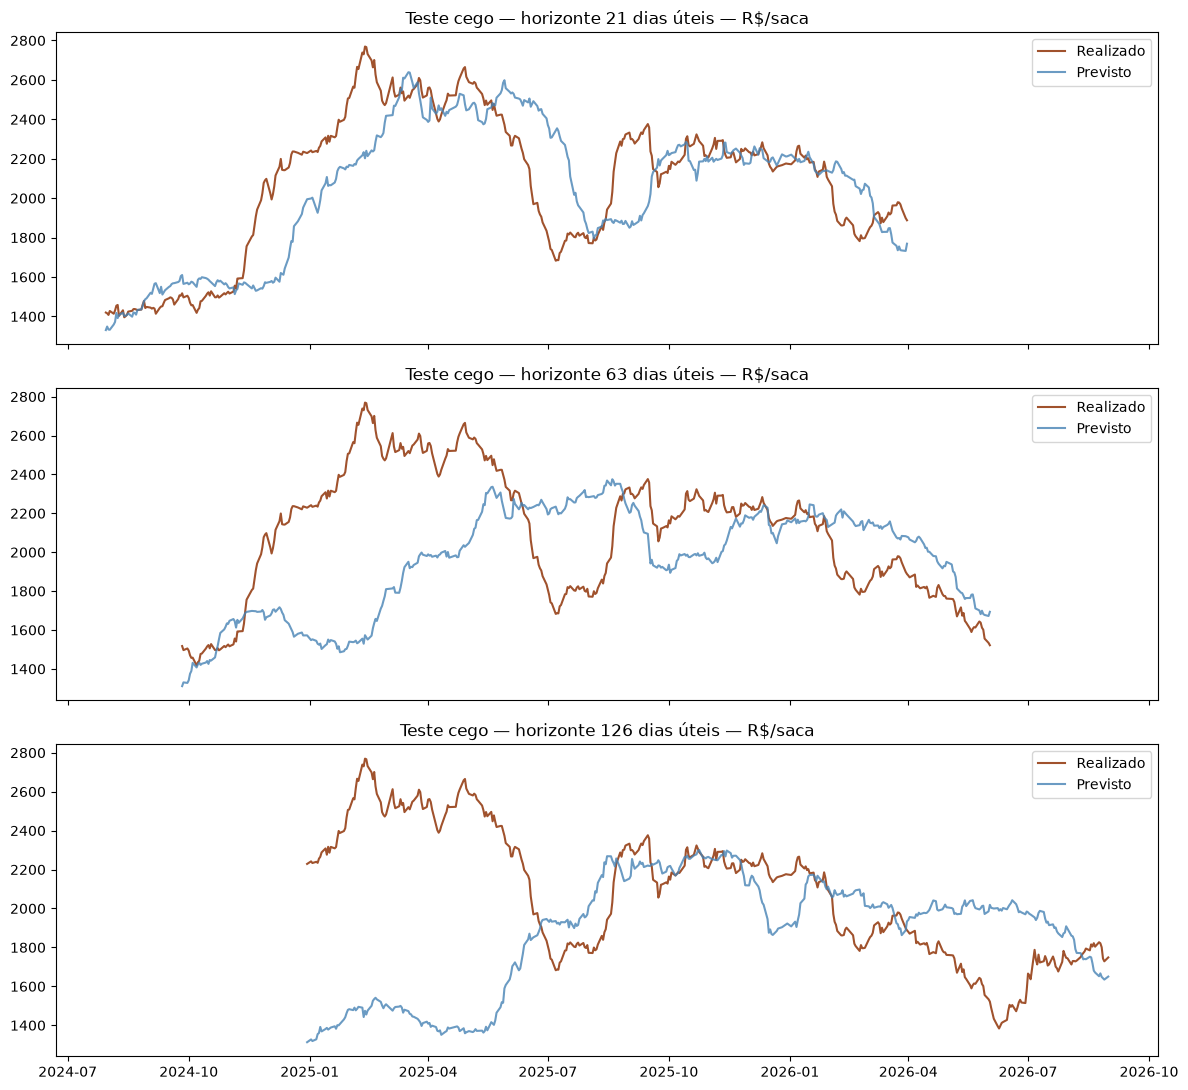

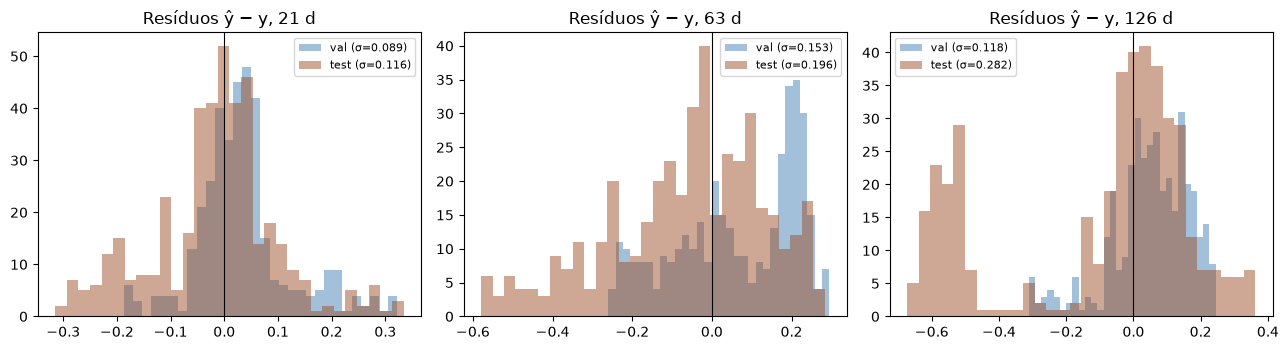

In [7]:
# C1/E6.3: previsto × realizado no TESTE e distribuição dos resíduos (val e teste)
for split, fname in [('test', '03_previsto_realizado_teste.png')]:
    sp = data[split]; pr = model.predict(sp['X'], verbose=0)
    fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(12, 11), sharex=True)
    for i, (h, ax) in enumerate(zip(HORIZONS, axes)):
        p_now = price.loc[sp['dates']].to_numpy()
        idx_f = df.index.get_indexer(sp['dates']) + h
        ax.plot(df.index[idx_f], price.iloc[idx_f].to_numpy(), color='sienna', label='Realizado')
        ax.plot(df.index[idx_f], p_now * np.exp(pr[:, i]), color='steelblue', alpha=0.8, label='Previsto')
        ax.set_title(f'Teste cego — horizonte {h} dias úteis — R$/saca'); ax.legend()
    plt.tight_layout(); plt.savefig(ROOT / 'reports' / 'figures' / fname, dpi=300, facecolor='white')

fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 3.6))
for i, (h, ax) in enumerate(zip(HORIZONS, axes)):
    for split, cor in [('val', 'steelblue'), ('test', 'sienna')]:
        sp = data[split]; res = model.predict(sp['X'], verbose=0)[:, i] - sp['y'][:, i]
        ax.hist(res, bins=30, alpha=0.5, color=cor, label=f'{split} (σ={res.std():.3f})')
    ax.axvline(0, color='k', lw=0.8); ax.set_title(f'Resíduos ŷ − y, {h} d'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / 'reports' / 'figures' / '03b_residuos.png', dpi=300, facecolor='white')